# fydp-3 — EX-0 (Primary, 2 classes) — **5-Fold Cross-Validation version**

**File tag:** `ex-0-primary_with_only_two_label-5fold`

This is the 5-fold version of the original `ex-0-primary_with_only_two_label` notebook.
The faculty asked for the **same 5-fold protocol in every experiment**, so all experiments can be
compared on common ground (single split vs 5-fold).

## What this experiment is
| Item | Value |
|---|---|
| Task | Binary (Normal = 0 vs Abnormal = 1, from `Anemia Predict`), BCE loss |
| Temporal pooling | Mean pooling (`mean`) |
| Demographic / symptom features | No |
| Fusion methods compared | `concat` vs `self_attention` |
| Best-checkpoint rule | highest validation ROC-AUC |

## What changed (ONLY the training part)
- The old **single train / validation split** is replaced by **5-fold stratified, patient-level cross-validation** over the train + validation pool.
- The **test set is still the same fixed test set** from the `Split` column. CV never touches it. Every fold's model is evaluated on it.
- Results are reported as **mean ± std across the 5 folds**, plus a **fold-averaged (ensemble)** confusion matrix and ROC curve, plus a **paired permutation test** (same as ex-2).
- `quick_run()` is replaced by `build_model_and_train()` (trains one model on one fold) and a fold loop in Step 10.

## What did NOT change
Data loading, class labels, frame sampling (32 yemas / 16 palmas), image preprocessing, backbone,
fusion modules, classifier head, loss, optimizer (Adam, lr = 1e-4), batch size and the held-out test set.

## Settings kept the same as ex-2
`N_FOLDS = 5`, `CV_EPOCHS = 10`, `CV_RANDOM_STATE = 42`, `PERMUTATION_ITERS = 2000`.

**Compute note:** 2 fusion types × 5 folds × 10 epochs = **100 training epochs** in total. Run Step 10b and Step 10c as separate cells.

Every step is numbered. Run top to bottom.

## Step 1 — Imports & GPU Setup

No Drive mount needed on Kaggle — inputs are already mounted at `/kaggle/input/`.


In [1]:
import os
import json
import random
from datetime import datetime

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

from sklearn.model_selection import StratifiedKFold   # NEW: needed for 5-fold CV

random.seed(42); np.random.seed(42); torch.manual_seed(42)

# --- GPU setup (Kaggle "GPU T4 x2" = two physical T4s visible to this container) ---
N_GPUS = torch.cuda.device_count() if torch.cuda.is_available() else 0
DEVICE = torch.device("cuda" if N_GPUS > 0 else "cpu")
USE_MULTI_GPU = N_GPUS > 1   # quick_run() wraps the model in nn.DataParallel when True

print("Using device:", DEVICE)
if N_GPUS > 0:
    for i in range(N_GPUS):
        print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")
print(f"USE_MULTI_GPU = {USE_MULTI_GPU}  ({N_GPUS} GPU(s) visible)")
if N_GPUS == 0:
    print("WARNING: no GPU visible - set Accelerator -> GPU T4 x2 in the notebook settings panel and restart.")

Using device: cuda
  GPU 0: Tesla T4
  GPU 1: Tesla T4
USE_MULTI_GPU = True  (2 GPU(s) visible)


## Step 1.5 — See What Kaggle Actually Mounted (run this first)

Prints the real folder tree under `/kaggle/input` up to 3 levels deep. Copy
the exact paths you see here into the manual override section in Step 2 —
this sidesteps auto-detection entirely, so there's no more guessing.


In [2]:
for root, dirs, files in os.walk("/kaggle/input"):
    depth = root.count(os.sep) - "/kaggle/input".count(os.sep)
    if depth > 3:
        dirs[:] = []
        continue
    indent = "  " * depth
    print(f"{indent}{os.path.basename(root) or root}/")
    for fn in sorted(files):
        print(f"{indent}  {fn}")


input/
  datasets/
    shimu080/
      dataset2/
        Dataset2.csv
      metadata/
        metadata.csv
      unas-palmas-yemas/


## Step 2 — Config: Paths & Settings (manual paths, with auto-detect fallback)

**Fill in `MANUAL_PATHS` below using what Step 1.5 printed** — that's the
real, verified folder tree, so there's no guessing involved. Paste each path
in as a plain string (right up to the folder that directly contains the
`Leve` / `Moderada` / `Normal` class folders, or the CSV file itself for
`csv`). Leave any entry as `None` to fall back to auto-detection for just
that one item — but manual is the reliable option, use it if auto-detect has
failed before.

`RESULTS_DIR` lives under `/kaggle/working/` — the only writable location on
Kaggle (`/kaggle/input/` is strictly read-only).


In [3]:
# --- Manual path overrides ---
# Copy the exact paths from the Step 1.5 output above. Example, if Step 1.5 printed:
#   yemas_frames/
#     yemas_frames/
#       Leve/
#       Moderada/
#       Normal/
# then the path you want is "/kaggle/input/yemas_frames/yemas_frames" (the
# folder that directly CONTAINS Leve/Moderada/Normal, not the folder above it).
MANUAL_PATHS = {
    "csv":    "/kaggle/input/datasets/shimu080/dataset2/Dataset2.csv",                     # <-- EDIT: exact path to Dataset2.csv
    "yemas":  "/kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames",                 # <-- EDIT
    "palmas": "/kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames",            # <-- EDIT
    "unas":   "/kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images",             # <-- EDIT
}

KAGGLE_INPUT_ROOT = "/kaggle/input"
RESULTS_DIR_ROOT = "/kaggle/working"
_available_inputs = sorted(os.listdir(KAGGLE_INPUT_ROOT)) if os.path.isdir(KAGGLE_INPUT_ROOT) else []

def find_input_dataset(*keywords):
    """Auto-detect fallback: first folder directly under /kaggle/input whose
    name contains any of the given keywords. Only used when the matching
    MANUAL_PATHS entry above is None."""
    for entry in _available_inputs:
        full = os.path.join(KAGGLE_INPUT_ROOT, entry)
        if os.path.isdir(full) and any(k in entry.lower() for k in keywords):
            return full
    return None

def descend_if_nested(base, *keywords):
    if base is None or not os.path.isdir(base):
        return base
    for child in sorted(os.listdir(base)):
        child_path = os.path.join(base, child)
        if os.path.isdir(child_path) and any(k in child.lower() for k in keywords):
            if any(os.path.isdir(os.path.join(child_path, g)) for g in os.listdir(child_path)):
                return child_path
    return base

def find_csv_in(base):
    if base is None or not os.path.isdir(base):
        return None
    for f in sorted(os.listdir(base)):
        if f.lower().endswith(".csv"):
            return os.path.join(base, f)
    return None

# Manual path wins if set; otherwise fall back to auto-detection.
SPLIT_CSV_PATH = MANUAL_PATHS["csv"] or find_csv_in(find_input_dataset("dataset2", "dataset"))
YEMAS_DIR  = MANUAL_PATHS["yemas"]  or descend_if_nested(find_input_dataset("yemas"), "yemas")
PALMAS_DIR = MANUAL_PATHS["palmas"] or descend_if_nested(find_input_dataset("palmas", "palma"), "palmas", "palma")
UNAS_DIR   = MANUAL_PATHS["unas"]   or descend_if_nested(find_input_dataset("unas"), "unas")
FALLBACK_METADATA_CSV = SPLIT_CSV_PATH  # same source on Kaggle, kept for Step 4 compatibility

# Dedicated results folder in the writable Kaggle output area.
STAMP_RESULTS_BY_DATE = True
_run_date = datetime.now().strftime("%Y-%m-%d")
RESULTS_DIR = os.path.join(RESULTS_DIR_ROOT, "fydp-3_results", "cv_ex0_binary")
if STAMP_RESULTS_BY_DATE:
    RESULTS_DIR = os.path.join(RESULTS_DIR, _run_date)
os.makedirs(RESULTS_DIR, exist_ok=True)

EXPECTED_FRAME_COUNTS = {"yemas": 32, "palmas": 16}  # frames SAMPLED from each subject's extracted-frame folder
FRAME_IMAGE_EXTS = (".jpg", ".jpeg", ".png")          # extracted yemas/palmas frame files
IMAGE_EXTS = (".jpg", ".jpeg", ".png")                # single cropped unas nail image

# Folder-name template for each subject's extracted frames, relative to
# <modality_dir>/<Class>/ . Default assumes .../yemas_frames/<Class>/<ID>/frame_0001.jpg etc.
# Edit if your frames sit in a differently-named subfolder, e.g. "{id}_frames".
FRAME_FOLDER_TEMPLATE = "{id}"

# --- Run settings ---
SUBSET_SIZE = None     # None = use the full split file; set a number for a faster partial run
BATCH_SIZE = 16 if USE_MULTI_GPU else 8   # bumped for 2x T4 so both GPUs stay fed
TEMPORAL_POOLING = "mean"   # "mean" or "bilstm"

# --- NEW: 5-fold cross-validation settings (identical to ex-2, so every experiment shares common ground) ---
N_FOLDS = 5              # patient-level StratifiedKFold over the train+validation pool
CV_EPOCHS = 10           # epochs per fold per fusion type (same value as ex-2)
CV_RANDOM_STATE = 42     # same seed in every experiment

# --- NEW: Significance testing settings (identical to ex-2) ---
PERMUTATION_ITERS = 2000
PERMUTATION_SEED = 42

print("SPLIT_CSV_PATH:", SPLIT_CSV_PATH or "NOT FOUND")
print("YEMAS_DIR     :", YEMAS_DIR or "NOT FOUND")
print("PALMAS_DIR    :", PALMAS_DIR or "NOT FOUND")
print("UNAS_DIR      :", UNAS_DIR or "NOT FOUND")
print("RESULTS_DIR   :", RESULTS_DIR, "(writable Kaggle output area)")
print(f"SUBSET_SIZE={SUBSET_SIZE}  N_FOLDS={N_FOLDS}  CV_EPOCHS={CV_EPOCHS}  BATCH_SIZE={BATCH_SIZE}  TEMPORAL_POOLING={TEMPORAL_POOLING}")
if not (SPLIT_CSV_PATH and YEMAS_DIR and PALMAS_DIR and UNAS_DIR):
    print("\nSome paths above are NOT FOUND. Check the MANUAL_PATHS dict against the "
          "Step 1.5 output and fix the ones that don't match.")

SPLIT_CSV_PATH: /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv
YEMAS_DIR     : /kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames
PALMAS_DIR    : /kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames
UNAS_DIR      : /kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images
RESULTS_DIR   : /kaggle/working/fydp-3_results/cv_ex0_binary/2026-10-23 (writable Kaggle output area)
SUBSET_SIZE=None  N_FOLDS=5  CV_EPOCHS=10  BATCH_SIZE=16  TEMPORAL_POOLING=mean


## Step 3 — Verify Resolved Dataset Paths

Asserts each path from Step 2 (manual or auto-detected) was actually found
and prints the class folders inside it, so a bad path is obvious immediately
instead of after a long training run.


In [4]:
for label, d in [("YEMAS", YEMAS_DIR), ("PALMAS", PALMAS_DIR), ("UNAS", UNAS_DIR)]:
    assert d is not None and os.path.isdir(d), (
        f"{label}_DIR not found at: {d}\n"
        f"Fix MANUAL_PATHS['{label.lower()}'] in Step 2 - copy the exact path from the "
        f"Step 1.5 listing above (the folder that directly contains Leve/Moderada/Normal)."
    )
    classes = [c for c in os.listdir(d) if os.path.isdir(os.path.join(d, c))]
    print(f"{label}_DIR -> {d}")
    print(f"  class folders found = {classes}")

assert SPLIT_CSV_PATH is not None and os.path.isfile(SPLIT_CSV_PATH), (
    f"Split CSV not found at: {SPLIT_CSV_PATH}\n"
    f"Fix MANUAL_PATHS['csv'] in Step 2 - copy the exact path to Dataset2.csv from the "
    f"Step 1.5 listing above."
)
print("\nSPLIT_CSV_PATH ->", SPLIT_CSV_PATH)


YEMAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames
  class folders found = ['Leve', 'Moderada', 'Normal']
PALMAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames
  class folders found = ['Leve', 'Moderada', 'Normal']
UNAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images
  class folders found = ['Leve', 'Moderada', 'Normal']

SPLIT_CSV_PATH -> /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv


## Step 4 — Load Your Split File

Drops blank filler rows, keeps `ID` / `Class` / `Anemia Predict` / `Split`.
Falls back to `dataset/metadata.csv` if `SPLIT_CSV_PATH` isn't found (note: the
fallback file may not have a `Split` column - handled below).

In [5]:
if os.path.isfile(SPLIT_CSV_PATH):
    metadata_source = SPLIT_CSV_PATH
elif os.path.isfile(FALLBACK_METADATA_CSV):
    metadata_source = FALLBACK_METADATA_CSV
    print(f"SPLIT_CSV_PATH not found - falling back to {FALLBACK_METADATA_CSV}")
else:
    raise FileNotFoundError(
        f"Could not find a metadata/split file at either:\n  {SPLIT_CSV_PATH}\n  {FALLBACK_METADATA_CSV}\n"
        f"Attach the dataset containing your split CSV as a Kaggle Input, or fix SPLIT_CSV_PATH in Step 2."
    )

print("Using metadata file:", metadata_source)
raw_df = pd.read_csv(metadata_source)
metadata_df = raw_df.dropna(subset=["ID"]).copy()

required_cols = ["ID", "Class", "Anemia Predict"]
missing_cols = [c for c in required_cols if c not in metadata_df.columns]
assert not missing_cols, f"Metadata file is missing required columns: {missing_cols}"
has_split_col = "Split" in metadata_df.columns

keep_cols = required_cols + (["Split"] if has_split_col else [])
metadata_df = metadata_df[keep_cols].reset_index(drop=True)
metadata_df["ID"] = metadata_df["ID"].astype(str).str.strip()
metadata_df["Class"] = metadata_df["Class"].astype(str).str.strip()
if has_split_col:
    metadata_df["Split"] = metadata_df["Split"].astype(str).str.strip()
else:
    print("WARNING: no 'Split' column in this metadata file - a fresh stratified 70/15/15 "
          "split will be created for you in Step 5 instead of using a provided one.")

print(f"{len(metadata_df)} subjects in metadata.")
if has_split_col:
    print(metadata_df["Split"].value_counts())

Using metadata file: /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv
909 subjects in metadata.
Split
train         636
validation    137
test          136
Name: count, dtype: int64


## Step 5 — Existence Check + Build Fixed Test Set + Train/Val Pool for CV

- Existence check (per-subject, all 3 modality files present) is unchanged.
- **New split structure for CV:** the `Split` column's `train` and `validation` rows are combined
  into a single **`trainval_df`** pool that Step 10's K-Fold loop will re-split internally (5 folds
  by default). The `test` rows become **`test_df`**, held out completely — never touched by CV,
  used only for final per-fold evaluation — so results stay comparable to the single-split
  notebooks.
- Patient-ID disjointness between `trainval_df` and `test_df` is asserted, same as before.

In [6]:
def subject_frame_folder(modality_dir, subj_class, subj_id):
    """Path to a subject's extracted-frame folder, e.g. dataset/yemas/<Class>/<ID>/."""
    folder_name = FRAME_FOLDER_TEMPLATE.format(id=subj_id)
    return os.path.join(modality_dir, subj_class, folder_name)

def list_frame_files(folder):
    """All extracted frame image paths in a subject's folder, sorted by filename."""
    if not os.path.isdir(folder):
        return []
    files = sorted(f for f in os.listdir(folder) if f.lower().endswith(FRAME_IMAGE_EXTS))
    return [os.path.join(folder, f) for f in files]

def find_subject_file(modality_dir, subj_class, subj_id, exts):
    for ext in exts:
        p = os.path.join(modality_dir, subj_class, subj_id + ext)
        if os.path.isfile(p):
            return p
    return None

def subject_exists(subj_id, subj_class):
    y = len(list_frame_files(subject_frame_folder(YEMAS_DIR, subj_class, subj_id))) > 0
    p = len(list_frame_files(subject_frame_folder(PALMAS_DIR, subj_class, subj_id))) > 0
    u = find_subject_file(UNAS_DIR, subj_class, subj_id, IMAGE_EXTS) is not None
    return y and p and u

tqdm.pandas(desc="Checking files exist")
metadata_df["exists_all_3"] = metadata_df.progress_apply(
    lambda r: subject_exists(r["ID"], r["Class"]), axis=1
)
usable_df = metadata_df[metadata_df["exists_all_3"]].reset_index(drop=True)
print(f"\n{len(usable_df)} / {len(metadata_df)} subjects have all 3 modality inputs on disk.")

if len(usable_df) == 0:
    sample_row = metadata_df.iloc[0]
    example_path = subject_frame_folder(YEMAS_DIR, sample_row["Class"], sample_row["ID"])
    raise RuntimeError(
        f"No subjects passed the existence check. Example frame folder tried:\n  {example_path}\n"
        f"Check DATASET_DIR / folder names in Steps 2-3, and confirm your extracted frames sit at "
        f"dataset/<modality>/<Class>/<ID>/*.jpg (edit FRAME_FOLDER_TEMPLATE in Step 2 if your subfolder "
        f"naming differs). Class folders found there were printed above, compare against Class values in "
        f"your metadata (e.g. '{sample_row['Class']}')."
    )

if SUBSET_SIZE is not None and len(usable_df) > SUBSET_SIZE:
    from sklearn.model_selection import train_test_split as _tts
    usable_df, _ = _tts(usable_df, train_size=SUBSET_SIZE, stratify=usable_df["Anemia Predict"], random_state=42)
    usable_df = usable_df.reset_index(drop=True)
    print(f"Subsampled down to {len(usable_df)} subjects (SUBSET_SIZE set).")

assert has_split_col, "Step 4 requires the Split column from Dataset2.csv to exist."
trainval_df = usable_df[usable_df["Split"].isin(["train", "validation"])].reset_index(drop=True)
test_df = usable_df[usable_df["Split"] == "test"].reset_index(drop=True)

trainval_ids, test_ids = set(trainval_df["ID"]), set(test_df["ID"])
assert trainval_ids.isdisjoint(test_ids)
print("PASS: trainval and test are patient-level disjoint.")

print(f"\ntrainval (train+validation, re-split by 5-fold CV in Step 10) = {len(trainval_df)}")
print(f"test (held out, untouched by CV)                              = {len(test_df)}")
print("trainval class balance:", trainval_df["Anemia Predict"].value_counts().to_dict())
print("test class balance:    ", test_df["Anemia Predict"].value_counts().to_dict())

Checking files exist:   0%|          | 0/909 [00:00<?, ?it/s]


737 / 909 subjects have all 3 modality inputs on disk.
PASS: trainval and test are patient-level disjoint.

trainval (train+validation, re-split by 5-fold CV in Step 10) = 627
test (held out, untouched by CV)                              = 110
trainval class balance: {0: 437, 1: 190}
test class balance:     {0: 79, 1: 31}


## Step 6 — Frame Sampling (Pre-Extracted) + Dataset Class

`sample_frame_paths` evenly picks `n_frames` image paths (32 for YEMAS, 16 for
PALMAS) out of whatever's already in each subject's extracted-frame folder —
no video decoding. `TriModalDataset` uses this for the two video-derived
modalities and loads the UNAS `.jpg` directly, same as before.

In [7]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
frame_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

def sample_frame_paths(all_paths, n_frames):
    """Evenly sample n_frames image paths from an already-extracted frame
    folder. If fewer frames exist than n_frames, all are used (the caller
    pads the rest by repeating the last frame)."""
    if len(all_paths) == 0:
        return []
    if len(all_paths) <= n_frames:
        return all_paths
    indices = np.linspace(0, len(all_paths) - 1, n_frames).astype(int)
    return [all_paths[i] for i in indices]


class TriModalDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def _load_frame_sequence(self, modality_dir, subj_class, subj_id, n_frames):
        folder = subject_frame_folder(modality_dir, subj_class, subj_id)
        all_paths = list_frame_files(folder)
        chosen = sample_frame_paths(all_paths, n_frames)
        imgs = [self.transform(Image.open(p).convert("RGB")) for p in chosen]
        while len(imgs) < n_frames:  # defensive pad, e.g. a subject with fewer frames than expected
            imgs.append(imgs[-1].clone() if imgs else torch.zeros(3, 224, 224))
        return torch.stack(imgs)

    def _load_image(self, modality_dir, subj_class, subj_id):
        img_path = find_subject_file(modality_dir, subj_class, subj_id, IMAGE_EXTS)
        if img_path:
            return self.transform(Image.open(img_path).convert("RGB"))
        return torch.zeros(3, 224, 224)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        subj_id, subj_class = row["ID"], row["Class"]
        yemas = self._load_frame_sequence(YEMAS_DIR, subj_class, subj_id, EXPECTED_FRAME_COUNTS["yemas"])
        palmas = self._load_frame_sequence(PALMAS_DIR, subj_class, subj_id, EXPECTED_FRAME_COUNTS["palmas"])
        unas = self._load_image(UNAS_DIR, subj_class, subj_id)
        label = torch.tensor(float(row["Anemia Predict"]))
        return yemas, palmas, unas, label

# Sanity check on one real subject before committing to a full run
_sample_row = trainval_df.iloc[0]
_sample_ds = TriModalDataset(trainval_df.iloc[[0]], frame_transform)
_y, _p, _u, _l = _sample_ds[0]
print(f"Sanity check on subject {_sample_row['ID']}: yemas={tuple(_y.shape)} "
      f"palmas={tuple(_p.shape)} unas={tuple(_u.shape)} label={_l.item()}")
print("TriModalDataset ready (loading pre-extracted frames, no video decoding).")

Sanity check on subject ID001: yemas=(32, 3, 224, 224) palmas=(16, 3, 224, 224) unas=(3, 224, 224) label=0.0
TriModalDataset ready (loading pre-extracted frames, no video decoding).


## Step 7 — Model Building Blocks (Encoder, Temporal Pool, Fusion)

Two fusion modes side by side: `ConcatFusion` (baseline, no learned interaction)
and `SelfAttentionFusion` (proposed — 3 modality tokens attend to each other,
then mean-pooled).

In [8]:
class FrameEncoder(nn.Module):
    def __init__(self, embed_dim=256):
        super().__init__()
        backbone = torchvision.models.resnet18(weights="IMAGENET1K_V1")
        self.backbone = nn.Sequential(*list(backbone.children())[:-1])
        self.proj = nn.Linear(512, embed_dim)

    def forward(self, x):
        return self.proj(self.backbone(x).flatten(1))


class TemporalPool(nn.Module):
    """mean: simple average over frames. bilstm: bidirectional LSTM, final
    hidden states concatenated + projected back to embed_dim."""
    def __init__(self, embed_dim=256, mode="mean", lstm_hidden=128):
        super().__init__()
        self.mode = mode
        if mode == "bilstm":
            self.lstm = nn.LSTM(embed_dim, lstm_hidden, batch_first=True, bidirectional=True)
            self.proj = nn.Linear(lstm_hidden * 2, embed_dim)

    def forward(self, x):
        if self.mode == "mean":
            return x.mean(dim=1)
        _, (h_n, _) = self.lstm(x)
        return self.proj(torch.cat([h_n[0], h_n[1]], dim=1))


class ConcatFusion(nn.Module):
    """Baseline: no learned cross-modal interaction."""
    def __init__(self, embed_dim=256):
        super().__init__()
        self.out_dim = embed_dim * 3

    def forward(self, v_yemas, v_palmas, v_unas):
        return torch.cat([v_yemas, v_palmas, v_unas], dim=1)


class SelfAttentionFusion(nn.Module):
    """Proposed: the 3 modality tokens attend to each other symmetrically."""
    def __init__(self, embed_dim=256, num_heads=4, dropout=0.3):
        super().__init__()
        self.modality_embed = nn.Parameter(torch.randn(3, embed_dim) * 0.02)
        layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=num_heads,
                                            dim_feedforward=embed_dim * 2,
                                            dropout=dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=1)
        self.out_dim = embed_dim

    def forward(self, v_yemas, v_palmas, v_unas):
        x = torch.stack([v_yemas, v_palmas, v_unas], dim=1) + self.modality_embed.unsqueeze(0)
        return self.encoder(x).mean(dim=1)

print("Model building blocks ready.")

Model building blocks ready.


## Step 8 — Full Model + Train/Eval Functions (Full Metrics)

`evaluate()` returns the full evaluation matrix: accuracy, precision,
recall/sensitivity, specificity, F1, ROC-AUC, and the confusion matrix — plus
raw probabilities/labels for the ROC curve.

`quick_run()` wraps the model in `nn.DataParallel` automatically when
`USE_MULTI_GPU` is True (i.e. both T4s are visible) — batches get split
across the 2 GPUs each step, no other code changes needed.

**5-fold change:** `quick_run()` is gone. It is replaced by **`build_model_and_train()`**, which trains
**one model on one fold** (same optimizer, loss and best-checkpoint rule as before). The loop over the
5 folds lives in Step 10.

In [9]:
class fydp_3Model(nn.Module):
    def __init__(self, fusion="concat", temporal_pooling="mean", embed_dim=256, dropout=0.3):
        super().__init__()
        self.yemas_encoder = FrameEncoder(embed_dim)
        self.palmas_encoder = FrameEncoder(embed_dim)
        self.unas_encoder = FrameEncoder(embed_dim)
        self.yemas_pool = TemporalPool(embed_dim, temporal_pooling)
        self.palmas_pool = TemporalPool(embed_dim, temporal_pooling)
        self.fusion = ConcatFusion(embed_dim) if fusion == "concat" else SelfAttentionFusion(embed_dim, dropout=dropout)
        hidden = 128 if fusion == "concat" else 64
        self.classifier = nn.Sequential(
            nn.Linear(self.fusion.out_dim, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, 1)
        )

    def forward(self, yemas, palmas, unas):
        B, Ty, C, H, W = yemas.shape
        _, Tp, _, _, _ = palmas.shape
        y = self.yemas_encoder(yemas.reshape(B * Ty, C, H, W)).view(B, Ty, -1)
        p = self.palmas_encoder(palmas.reshape(B * Tp, C, H, W)).view(B, Tp, -1)
        v_yemas, v_palmas = self.yemas_pool(y), self.palmas_pool(p)
        v_unas = self.unas_encoder(unas)
        fused = self.fusion(v_yemas, v_palmas, v_unas)
        return self.classifier(fused).squeeze(1)


def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total = 0.0
    for yemas, palmas, unas, labels in tqdm(loader, desc="train", leave=False):
        yemas, palmas, unas, labels = yemas.to(DEVICE), palmas.to(DEVICE), unas.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(yemas, palmas, unas), labels)
        loss.backward(); optimizer.step()
        total += loss.item() * len(labels)
    return total / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, criterion):
    """Full evaluation matrix: accuracy, precision, recall/sensitivity,
    specificity, F1, ROC-AUC, confusion matrix, plus raw probs/labels for ROC plots."""
    model.eval()
    total, probs_all, labels_all = 0.0, [], []
    for yemas, palmas, unas, labels in tqdm(loader, desc="eval", leave=False):
        yemas, palmas, unas, labels = yemas.to(DEVICE), palmas.to(DEVICE), unas.to(DEVICE), labels.to(DEVICE)
        logits = model(yemas, palmas, unas)
        total += criterion(logits, labels).item() * len(labels)
        probs_all.append(torch.sigmoid(logits).cpu().numpy())
        labels_all.append(labels.cpu().numpy())
    probs, labels = np.concatenate(probs_all), np.concatenate(labels_all)
    preds = (probs >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, preds, labels=[0, 1]).ravel()
    metrics = {
        "loss": total / len(loader.dataset),
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, zero_division=0),
        "recall_sensitivity": recall_score(labels, preds, zero_division=0),
        "specificity": tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        "f1": f1_score(labels, preds, zero_division=0),
        "roc_auc": roc_auc_score(labels, probs) if len(set(labels)) > 1 else float("nan"),
        "confusion_matrix": [[int(tn), int(fp)], [int(fn), int(tp)]],
    }
    return metrics, probs, labels


def build_model_and_train(fusion_name, fold_train_df, fold_val_df, epochs,
                          temporal_pooling=TEMPORAL_POOLING):
    """Trains ONE model on ONE fold (this replaces quick_run(): it is called once per fold from
    Step 10). Same optimizer / loss / checkpoint rule as before: Adam lr=1e-4, BCEWithLogitsLoss,
    best checkpoint = highest validation ROC-AUC.
    Returns (model loaded with its best weights, per-epoch history DataFrame)."""
    loader_kwargs = dict(num_workers=2, pin_memory=(DEVICE.type == "cuda"))
    train_loader = DataLoader(TriModalDataset(fold_train_df, frame_transform),
                               batch_size=BATCH_SIZE, shuffle=True, **loader_kwargs)
    val_loader = DataLoader(TriModalDataset(fold_val_df, frame_transform),
                             batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)

    model = fydp_3Model(fusion=fusion_name, temporal_pooling=temporal_pooling).to(DEVICE)
    if USE_MULTI_GPU:
        model = nn.DataParallel(model)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    history = []
    best_val_auc, best_state = -1, None
    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        val_metrics, _, _ = evaluate(model, val_loader, criterion)
        history.append({"epoch": epoch, "train_loss": train_loss,
                         "val_loss": val_metrics["loss"], "val_accuracy": val_metrics["accuracy"],
                         "val_roc_auc": val_metrics["roc_auc"]})
        print(f"  Epoch {epoch}/{epochs}  train_loss={train_loss:.4f}  val_loss={val_metrics['loss']:.4f}  "
              f"val_acc={val_metrics['accuracy']:.3f}  val_auc={val_metrics['roc_auc']:.3f}")
        if val_metrics["roc_auc"] == val_metrics["roc_auc"] and val_metrics["roc_auc"] > best_val_auc:
            best_val_auc = val_metrics["roc_auc"]
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(history)


print("Training/eval utilities ready (binary classification, one model per fold).")

Training/eval utilities ready (binary classification, one model per fold).


## Step 10 — 5-Fold Cross-Validation Training Loop (Concat vs Self-Attention)

**This is the only part that changed compared with the single-split notebook.**

- **Step 10a — Fold setup (run once).** Makes the 5 stratified, patient-level splits of `trainval_df` once and stores them in `fold_splits`. Both fusion types use the **same** folds, which the paired permutation test in Step 11 needs. Do **not** re-run 10a between 10b and 10c.
- **Step 10b — Concat fusion, 5 folds.** For each fold:
  1. Split into this fold's train / validation subjects (patient-level, stratified).
  2. Train for `CV_EPOCHS` epochs and keep the best checkpoint (highest validation ROC-AUC).
  3. Evaluate that checkpoint on the **fixed test set** and save the metrics and probabilities.
- **Step 10c — Self-attention fusion, 5 folds.** Exactly the same, with `self_attention`.
- **Step 10d — Combine + save.** Puts all fold results in `fold_results_df` and writes CSV files to `RESULTS_DIR`.

Cell A — setup (run once)

In [10]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=CV_RANDOM_STATE)
test_loader_kwargs = dict(num_workers=2, pin_memory=(DEVICE.type == "cuda"))

trainval_labels = trainval_df["Anemia Predict"].astype(int).to_numpy()
fold_splits = list(skf.split(trainval_df, trainval_labels))  # shared by both fusion cells below

fold_results = []
fold_test_probs = {"concat": [], "self_attention": []}
fold_histories = {"concat": [], "self_attention": []}

Cell B — concat, 5-fold

In [11]:
import gc

fusion_name = "concat"
print(f"\n================ FUSION = {fusion_name} ================")

for fold_idx, (train_idx, val_idx) in enumerate(fold_splits, start=1):
    fold_train_df = trainval_df.iloc[train_idx].reset_index(drop=True)
    fold_val_df = trainval_df.iloc[val_idx].reset_index(drop=True)
    print(f"\n----- fold {fold_idx}/{N_FOLDS} (train={len(fold_train_df)} val={len(fold_val_df)}) -----")

    test_loader = DataLoader(TriModalDataset(test_df, frame_transform),
                              batch_size=BATCH_SIZE, shuffle=False, **test_loader_kwargs)

    model, fold_hist = build_model_and_train(fusion_name, fold_train_df, fold_val_df, CV_EPOCHS)
    fold_hist["fold"] = fold_idx
    fold_hist["fusion"] = fusion_name
    fold_histories[fusion_name].append(fold_hist)

    criterion = nn.BCEWithLogitsLoss()
    test_metrics, test_probs, test_labels = evaluate(model, test_loader, criterion)
    print(f"  fold {fold_idx} [{fusion_name}] TEST: acc={test_metrics['accuracy']:.3f} "
          f"F1={test_metrics['f1']:.3f} AUC={test_metrics['roc_auc']:.3f}")

    fold_results.append({"fusion": fusion_name, "fold": fold_idx, **{
        k: v for k, v in test_metrics.items() if k != "confusion_matrix"
    }})
    fold_test_probs[fusion_name].append(test_probs)

    torch.save(model.state_dict(), os.path.join(RESULTS_DIR, f"{fusion_name}_fold{fold_idx}_model.pt"))

    # free GPU memory before the next fold starts
    del model, criterion
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


================ FUSION = concat ================

----- fold 1/5 (train=501 val=126) -----
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 173MB/s]


train:   0%|          | 0/32 [00:00<?, ?it/s]

eval:   0%|          | 0/8 [00:00<?, ?it/s]

  Epoch 1/10  train_loss=0.5698  val_loss=0.5237  val_acc=0.698  val_auc=0.752


train:   0%|          | 0/32 [00:00<?, ?it/s]

... (152 outputs left out)

eval:   0%|          | 0/8 [00:00<?, ?it/s]

  Epoch 10/10  train_loss=0.0958  val_loss=1.5309  val_acc=0.720  val_auc=0.668


eval:   0%|          | 0/7 [00:00<?, ?it/s]

  fold 5 [concat] TEST: acc=0.691 F1=0.190 AUC=0.652


Cell C — self_attention, 5-fold

In [12]:
import gc

fusion_name = "self_attention"
print(f"\n================ FUSION = {fusion_name} ================")

for fold_idx, (train_idx, val_idx) in enumerate(fold_splits, start=1):
    fold_train_df = trainval_df.iloc[train_idx].reset_index(drop=True)
    fold_val_df = trainval_df.iloc[val_idx].reset_index(drop=True)
    print(f"\n----- fold {fold_idx}/{N_FOLDS} (train={len(fold_train_df)} val={len(fold_val_df)}) -----")

    test_loader = DataLoader(TriModalDataset(test_df, frame_transform),
                              batch_size=BATCH_SIZE, shuffle=False, **test_loader_kwargs)

    model, fold_hist = build_model_and_train(fusion_name, fold_train_df, fold_val_df, CV_EPOCHS)
    fold_hist["fold"] = fold_idx
    fold_hist["fusion"] = fusion_name
    fold_histories[fusion_name].append(fold_hist)

    criterion = nn.BCEWithLogitsLoss()
    test_metrics, test_probs, test_labels = evaluate(model, test_loader, criterion)
    print(f"  fold {fold_idx} [{fusion_name}] TEST: acc={test_metrics['accuracy']:.3f} "
          f"F1={test_metrics['f1']:.3f} AUC={test_metrics['roc_auc']:.3f}")

    fold_results.append({"fusion": fusion_name, "fold": fold_idx, **{
        k: v for k, v in test_metrics.items() if k != "confusion_matrix"
    }})
    fold_test_probs[fusion_name].append(test_probs)

    torch.save(model.state_dict(), os.path.join(RESULTS_DIR, f"{fusion_name}_fold{fold_idx}_model.pt"))

    # free GPU memory before the next fold starts
    del model, criterion
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


================ FUSION = self_attention ================

----- fold 1/5 (train=501 val=126) -----


train:   0%|          | 0/32 [00:00<?, ?it/s]

eval:   0%|          | 0/8 [00:00<?, ?it/s]

  Epoch 1/10  train_loss=0.5863  val_loss=0.5405  val_acc=0.683  val_auc=0.752


train:   0%|          | 0/32 [00:00<?, ?it/s]

eval:   0%|          | 0/8 [00:00<?, ?it/s]

... (151 outputs left out)

eval:   0%|          | 0/8 [00:00<?, ?it/s]

  Epoch 10/10  train_loss=0.1001  val_loss=0.9298  val_acc=0.664  val_auc=0.743


eval:   0%|          | 0/7 [00:00<?, ?it/s]

  fold 5 [self_attention] TEST: acc=0.682 F1=0.507 AUC=0.761


Cell D — combine + save

In [13]:
fold_results_df = pd.DataFrame(fold_results)
fold_results_df.to_csv(os.path.join(RESULTS_DIR, "cv_fold_results.csv"), index=False)
for fusion_name in ["concat", "self_attention"]:
    pd.concat(fold_histories[fusion_name], ignore_index=True).to_csv(
        os.path.join(RESULTS_DIR, f"{fusion_name}_cv_history.csv"), index=False
    )

print("\n\n=== Per-fold test results ===")
print(fold_results_df.to_string(index=False))
print("\nFolds per fusion (each should list 1..N_FOLDS exactly once):")
print(fold_results_df.groupby("fusion")["fold"].apply(list))



=== Per-fold test results ===
        fusion  fold     loss  accuracy  precision  recall_sensitivity  specificity       f1  roc_auc
        concat     1 0.504327  0.700000   0.333333            0.064516     0.949367 0.108108 0.760719
        concat     2 0.996218  0.736364   0.600000            0.193548     0.949367 0.292683 0.752144
        concat     3 0.492578  0.781818   0.640000            0.516129     0.886076 0.571429 0.802368
        concat     4 0.577419  0.700000   0.375000            0.096774     0.936709 0.153846 0.655370
        concat     5 1.238109  0.690909   0.363636            0.129032     0.911392 0.190476 0.651695
self_attention     1 0.521474  0.736364   0.666667            0.129032     0.974684 0.216216 0.775419
self_attention     2 0.701420  0.645455   0.420000            0.677419     0.632911 0.518519 0.735402
self_attention     3 0.770560  0.636364   0.384615            0.483871     0.696203 0.428571 0.703961
self_attention     4 0.835708  0.718182   0.500000

## Step 11 — Aggregate CV Results (Mean ± Std) + Paired Permutation Significance Test

- Mean ± std of every test metric across the 5 folds, per fusion type. These are the headline numbers.
- A **paired sign-flip permutation test** (2000 iterations) on the per-fold **F1** and **ROC-AUC** of
  `concat` vs `self_attention`. It is "paired" because both fusion types used the exact same folds and the same test set.

In [14]:
BIN_METRICS = ["accuracy", "precision", "recall_sensitivity", "specificity", "f1", "roc_auc"]

summary_rows = []
for fusion_name in ["concat", "self_attention"]:
    sub = fold_results_df[fold_results_df["fusion"] == fusion_name]
    row = {"fusion": fusion_name}
    for metric in BIN_METRICS:
        row[f"{metric}_mean"] = sub[metric].mean()
        row[f"{metric}_std"] = sub[metric].std()
    summary_rows.append(row)
cv_summary_df = pd.DataFrame(summary_rows)
print("=== CV summary (mean +/- std across folds) ===")
print(cv_summary_df.T.to_string(header=False))
cv_summary_df.to_csv(os.path.join(RESULTS_DIR, "cv_summary_mean_std.csv"), index=False)


def paired_permutation_test(scores_a, scores_b, n_iter=PERMUTATION_ITERS, seed=PERMUTATION_SEED):
    """Sign-flip paired permutation test on the per-fold score differences (a - b). Returns
    (observed_mean_diff, two_sided_p_value)."""
    scores_a, scores_b = np.asarray(scores_a, dtype=np.float64), np.asarray(scores_b, dtype=np.float64)
    diffs = scores_a - scores_b
    observed = diffs.mean()
    rng = np.random.default_rng(seed)
    count = 0
    for _ in range(n_iter):
        signs = rng.choice([-1.0, 1.0], size=len(diffs))
        permuted_mean = (diffs * signs).mean()
        if abs(permuted_mean) >= abs(observed):
            count += 1
    p_value = (count + 1) / (n_iter + 1)
    return float(observed), float(p_value)


perm_results = {}
for metric in ["f1", "roc_auc"]:
    concat_scores = fold_results_df.loc[fold_results_df["fusion"] == "concat", metric].to_numpy()
    selfattn_scores = fold_results_df.loc[fold_results_df["fusion"] == "self_attention", metric].to_numpy()
    assert len(concat_scores) == len(selfattn_scores) == N_FOLDS, "Fold counts mismatch between fusion types - check Step 10."
    observed_diff, p_value = paired_permutation_test(selfattn_scores, concat_scores)
    perm_results[metric] = {"observed_diff_selfattn_minus_concat": observed_diff, "p_value": p_value,
                            "n_iter": PERMUTATION_ITERS, "n_folds": N_FOLDS}
    print(f"\n=== Paired permutation test: self_attention vs concat, {metric} per fold ===")
    print(f"concat     per-fold {metric}: {concat_scores.round(3).tolist()}")
    print(f"self_attn  per-fold {metric}: {selfattn_scores.round(3).tolist()}")
    print(f"Observed mean difference (self_attention - concat): {observed_diff:+.4f}")
    print(f"Two-sided permutation p-value ({PERMUTATION_ITERS} iterations): {p_value:.4f}")
    if p_value < 0.05:
        print("=> Statistically significant difference at alpha=0.05.")
    else:
        print("=> NOT statistically significant at alpha=0.05 - do not claim one fusion method is "
              "reliably better based on this sample size.")

with open(os.path.join(RESULTS_DIR, "permutation_test_result.json"), "w") as f:
    json.dump(perm_results, f, indent=2)

=== CV summary (mean +/- std across folds) ===
fusion                     concat  self_attention
accuracy_mean            0.721818        0.683636
accuracy_std             0.037812        0.043788
precision_mean           0.462394        0.484256
precision_std            0.145367        0.110399
recall_sensitivity_mean       0.2        0.406452
recall_sensitivity_std   0.183049        0.248408
specificity_mean         0.926582        0.792405
specificity_std          0.027442        0.153107
f1_mean                  0.263308         0.38285
f1_std                   0.185185        0.144043
roc_auc_mean             0.724459        0.724214
roc_auc_std              0.067489        0.051659

=== Paired permutation test: self_attention vs concat, f1 per fold ===
concat     per-fold f1: [0.108, 0.293, 0.571, 0.154, 0.19]
self_attn  per-fold f1: [0.216, 0.519, 0.429, 0.244, 0.507]
Observed mean difference (self_attention - concat): +0.1195
Two-sided permutation p-value (2000 iterations): 0.2

## Step 12 — Fold-Averaged Confusion Matrices + ROC Curves

The same fixed test set is scored once per fold. The 5 probability arrays per fusion type are
**averaged into one ensemble prediction** (threshold 0.5), and the confusion matrix and ROC curve are drawn from it.

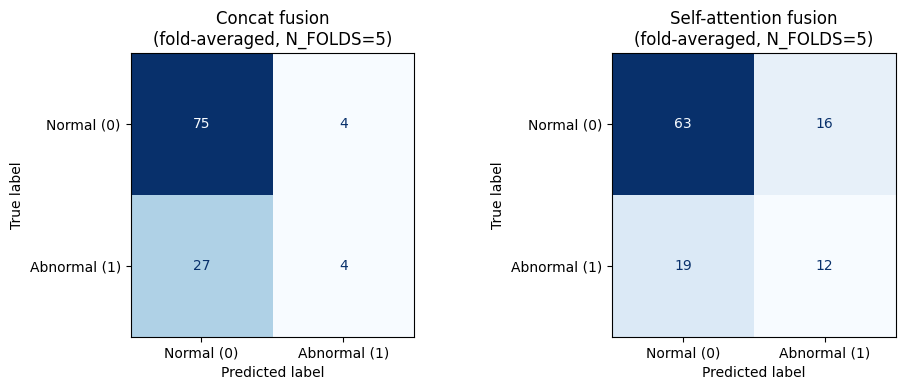

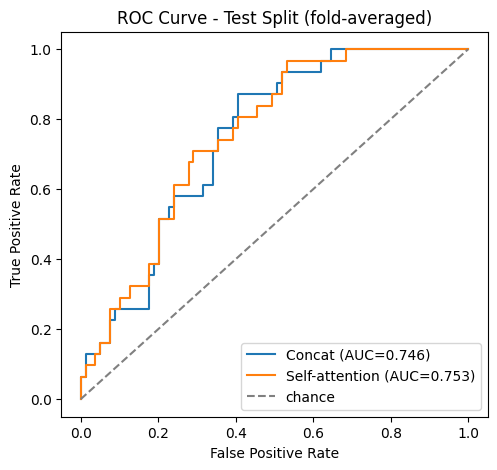

In [15]:
from sklearn.metrics import roc_curve, auc as sk_auc

true_labels = test_df["Anemia Predict"].astype(int).to_numpy()

# Average the N_FOLDS probability arrays into one ensemble prediction on the fixed test set.
ensemble_probs = {fusion_name: np.mean(np.stack(fold_test_probs[fusion_name], axis=0), axis=0)
                   for fusion_name in ["concat", "self_attention"]}
ensemble_preds = {fusion_name: (probs >= 0.5).astype(int) for fusion_name, probs in ensemble_probs.items()}
ensemble_cms = {fusion_name: confusion_matrix(true_labels, preds, labels=[0, 1])
                 for fusion_name, preds in ensemble_preds.items()}

# --- Confusion matrices (fold-averaged / ensembled) ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name, key in [(axes[0], "Concat fusion", "concat"), (axes[1], "Self-attention fusion", "self_attention")]:
    disp = ConfusionMatrixDisplay(confusion_matrix=ensemble_cms[key], display_labels=["Normal (0)", "Abnormal (1)"])
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\n(fold-averaged, N_FOLDS={N_FOLDS})")
plt.tight_layout()
cm_png = os.path.join(RESULTS_DIR, "confusion_matrices_fold_averaged.png")
plt.savefig(cm_png, dpi=150, bbox_inches="tight")
plt.show()

# --- ROC curves (fold-averaged probabilities) ---
fig, ax = plt.subplots(figsize=(5.5, 5))
for name, key in [("Concat", "concat"), ("Self-attention", "self_attention")]:
    fpr, tpr, _ = roc_curve(true_labels, ensemble_probs[key])
    ax.plot(fpr, tpr, label=f"{name} (AUC={sk_auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray", label="chance")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve - Test Split (fold-averaged)"); ax.legend(loc="lower right")
roc_png = os.path.join(RESULTS_DIR, "roc_curves_fold_averaged.png")
plt.savefig(roc_png, dpi=150, bbox_inches="tight")
plt.show()

Loss curves — concat vs self_attention (mean across folds)

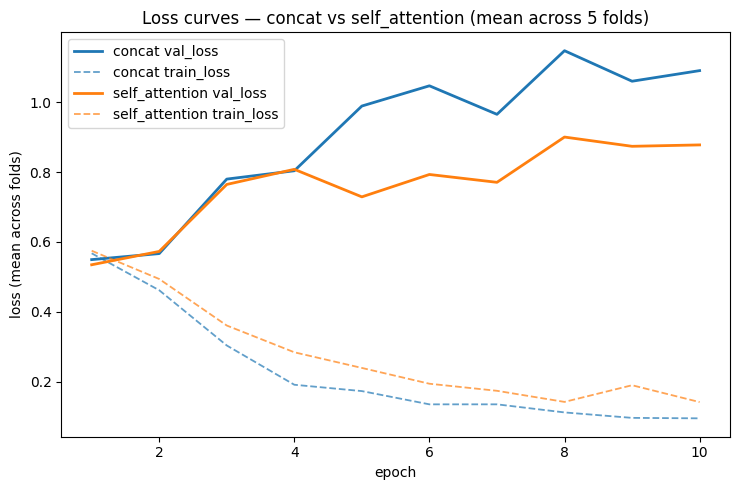

In [16]:
fig, ax = plt.subplots(figsize=(7.5, 5))

colors = {"concat": "tab:blue", "self_attention": "tab:orange"}

for fusion_name in ["concat", "self_attention"]:
    hist_df = pd.concat(fold_histories[fusion_name], ignore_index=True)
    mean_val_loss = hist_df.groupby("epoch")["val_loss"].mean()
    mean_train_loss = hist_df.groupby("epoch")["train_loss"].mean()

    ax.plot(mean_val_loss.index, mean_val_loss.values,
            color=colors[fusion_name], linestyle="-", linewidth=2,
            label=f"{fusion_name} val_loss")
    ax.plot(mean_train_loss.index, mean_train_loss.values,
            color=colors[fusion_name], linestyle="--", linewidth=1.3, alpha=0.7,
            label=f"{fusion_name} train_loss")

ax.set_xlabel("epoch")
ax.set_ylabel("loss (mean across folds)")
ax.set_title(f"Loss curves \u2014 concat vs self_attention (mean across {N_FOLDS} folds)")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "loss_curves_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

Per-fold F1 / ROC-AUC comparison

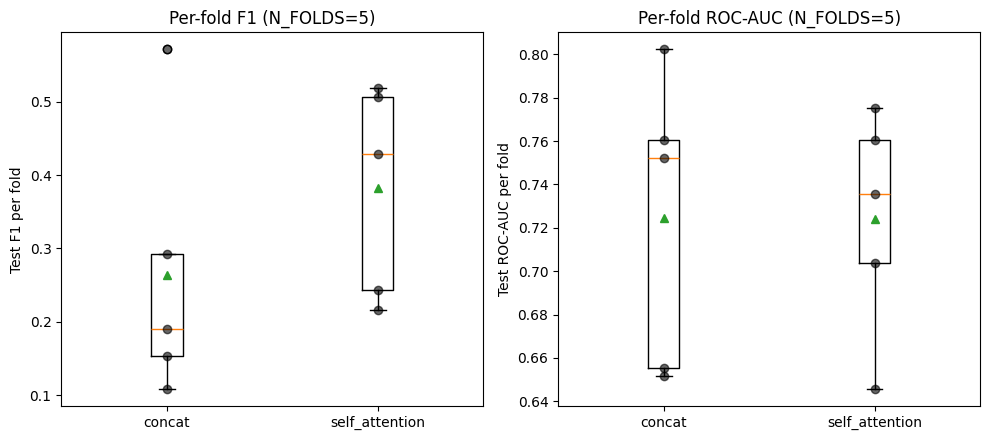

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, metric, title in [(axes[0], "f1", "F1"), (axes[1], "roc_auc", "ROC-AUC")]:
    concat_scores = fold_results_df.loc[fold_results_df["fusion"] == "concat", metric].to_numpy()
    selfattn_scores = fold_results_df.loc[fold_results_df["fusion"] == "self_attention", metric].to_numpy()
    ax.boxplot([concat_scores, selfattn_scores], showmeans=True)
    ax.set_xticks([1, 2]); ax.set_xticklabels(["concat", "self_attention"])
    for i, scores in enumerate([concat_scores, selfattn_scores], start=1):
        ax.scatter([i] * len(scores), scores, alpha=0.6, color="black", zorder=3)
    ax.set_ylabel(f"Test {title} per fold")
    ax.set_title(f"Per-fold {title} (N_FOLDS={N_FOLDS})")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "per_fold_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

## Step 13 — Final Comparison Table: Concat vs Self-Attention (5-fold)

Fold-averaged (ensemble) test metrics for the two fusion methods on the same fixed test set, plus the mean ± std of F1 and ROC-AUC across folds.

                     model  accuracy  precision  recall_sensitivity  specificity       f1  roc_auc  f1_cv_mean  f1_cv_std  roc_auc_cv_mean  roc_auc_cv_std
        deep_concat_fusion  0.718182   0.500000            0.129032     0.949367 0.205128 0.746427    0.263308   0.185185         0.724459        0.067489
deep_self_attention_fusion  0.681818   0.428571            0.387097     0.797468 0.406780 0.753369    0.382850   0.144043         0.724214        0.051659


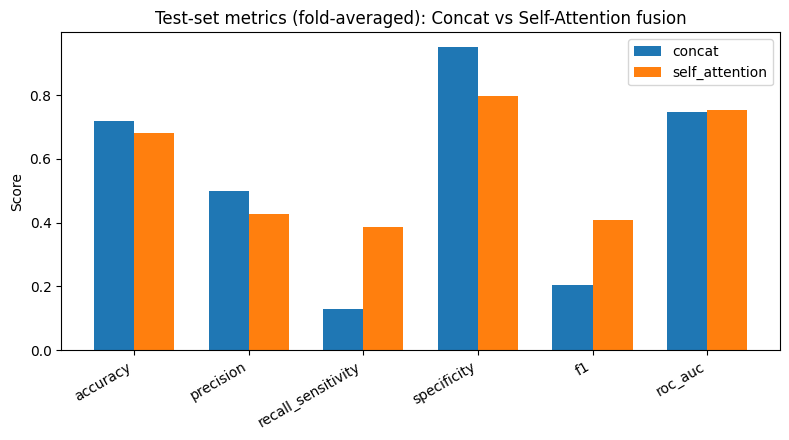


All outputs saved to: /kaggle/working/fydp-3_results/cv_ex0_binary/2026-10-23


In [18]:
def ensemble_metrics(key):
    probs = ensemble_probs[key]
    preds = (probs >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(true_labels, preds, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(true_labels, preds),
        "precision": precision_score(true_labels, preds, zero_division=0),
        "recall_sensitivity": recall_score(true_labels, preds, zero_division=0),
        "specificity": tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        "f1": f1_score(true_labels, preds, zero_division=0),
        "roc_auc": roc_auc_score(true_labels, probs),
    }

final_rows = []
for key, label in [("concat", "deep_concat_fusion"), ("self_attention", "deep_self_attention_fusion")]:
    row = {"model": label}
    row.update(ensemble_metrics(key))
    cv_row = cv_summary_df[cv_summary_df["fusion"] == key].iloc[0]
    row["f1_cv_mean"] = cv_row["f1_mean"]
    row["f1_cv_std"] = cv_row["f1_std"]
    row["roc_auc_cv_mean"] = cv_row["roc_auc_mean"]
    row["roc_auc_cv_std"] = cv_row["roc_auc_std"]
    final_rows.append(row)

final_compare_df = pd.DataFrame(final_rows)
print(final_compare_df.to_string(index=False))
final_compare_df.to_csv(os.path.join(RESULTS_DIR, "final_model_comparison.csv"), index=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
metric_names = ["accuracy", "precision", "recall_sensitivity", "specificity", "f1", "roc_auc"]
x = np.arange(len(metric_names))
width = 0.35
ax.bar(x - width/2, final_compare_df.loc[final_compare_df["model"] == "deep_concat_fusion", metric_names].values[0], width, label="concat")
ax.bar(x + width/2, final_compare_df.loc[final_compare_df["model"] == "deep_self_attention_fusion", metric_names].values[0], width, label="self_attention")
ax.set_xticks(x); ax.set_xticklabels(metric_names, rotation=30, ha="right")
ax.set_ylabel("Score"); ax.set_title("Test-set metrics (fold-averaged): Concat vs Self-Attention fusion")
ax.legend()
plt.tight_layout()
final_png = os.path.join(RESULTS_DIR, "final_model_comparison_bar.png")
plt.savefig(final_png, dpi=150, bbox_inches="tight")
plt.show()

print("\nAll outputs saved to:", RESULTS_DIR)

## Step 14 — Zip Everything & Get a Download Link

Bundles every file written to `RESULTS_DIR` this run — per-fold histories/metrics, the CV summary,
the permutation-test result, tabular-baseline results, confusion matrices, ROC curves, the final
comparison table/bar chart, and all per-fold model weights — into a single `.zip` in
`/kaggle/working/`.

In [19]:
import shutil
from IPython.display import FileLink, display

zip_base = os.path.join(RESULTS_DIR_ROOT, f"fydp-3_ex-0-primary_with_only_two_label-5fold_results_{_run_date}")
zip_path = shutil.make_archive(zip_base, "zip", RESULTS_DIR)

print("Files bundled into the zip:")
for root, _, files in os.walk(RESULTS_DIR):
    for fn in sorted(files):
        full = os.path.join(root, fn)
        print(f"  {os.path.relpath(full, RESULTS_DIR)}  ({os.path.getsize(full) / 1024:.1f} KB)")

zip_size_mb = os.path.getsize(zip_path) / (1024 * 1024)
print(f"\nZip written to: {zip_path}  ({zip_size_mb:.1f} MB)")
print("Click below to download it (it's also visible under this notebook's Output tab):")
display(FileLink(os.path.relpath(zip_path, os.getcwd())))

Files bundled into the zip:
  concat_cv_history.csv  (3.9 KB)
  concat_fold1_model.pt  (133149.8 KB)
  concat_fold2_model.pt  (133149.8 KB)
  concat_fold3_model.pt  (133149.8 KB)
  concat_fold4_model.pt  (133149.8 KB)
  concat_fold5_model.pt  (133149.8 KB)
  confusion_matrices_fold_averaged.png  (39.6 KB)
  cv_fold_results.csv  (1.4 KB)
  cv_summary_mean_std.csv  (0.6 KB)
  final_model_comparison.csv  (0.5 KB)
  final_model_comparison_bar.png  (49.7 KB)
  loss_curves_comparison.png  (86.2 KB)
  per_fold_comparison.png  (55.8 KB)
  permutation_test_result.json  (0.3 KB)
  roc_curves_fold_averaged.png  (54.4 KB)
  self_attention_cv_history.csv  (4.3 KB)
  self_attention_fold1_model.pt  (134899.5 KB)
  self_attention_fold2_model.pt  (134899.5 KB)
  self_attention_fold3_model.pt  (134899.5 KB)
  self_attention_fold4_model.pt  (134899.5 KB)
  self_attention_fold5_model.pt  (134899.5 KB)

Zip written to: /kaggle/working/fydp-3_ex-0-primary_with_only_two_label-5fold_results_2026-10-23.zip  (1

/kaggle/working/fydp-3_ex-0-primary_with_only_two_label-5fold_results_2026-10-23.zip